# DEV · Problema 1 · CardioRitmo: tamizaje de latidos
**Examen del Parcial II · Aprendizaje Automático III (IN1042) · Otoño 2026**
**Equipo:** Emilio Frausto, Juan, Rodrigo Rosales (cuaderno DEV)
**Datos:** ECG5000 (archivo UCR de series de tiempo; base BIDMC de PhysioNet), cargado con el código indicado por el cliente desde https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv

### El caso
CardioRitmo (empresa ficticia) fabrica monitores Holter, que registran el electrocardiograma de un paciente durante 24 horas (más de 100,000 latidos). Hoy un técnico revisa cada registro a mano. La empresa quiere que el **monitor marque los latidos anormales** para que el cardiólogo revise solo esos.

**Especificaciones del cliente** (en la prueba, con el umbral de 0.5):
- **Sensibilidad ≥ 95 %:** de cada 100 latidos anormales, que marque al menos 95.
- **Especificidad ≥ 95 %:** de cada 100 latidos normales, que no marque más de 5 como anormales.
- **El modelo debe caber en el monitor:** 20,000 parámetros o menos.
- El cliente quiere saber **con honestidad con qué pacientes funcionaría**.

### Cómo está organizado este cuaderno
1. Entorno y utilidades.
2. Datos y exploración (con gráficas).
3. Preparación: la división indicada, sin fuga, y la transformación de los datos.
4. Línea base trivial.
5. Modelos del parcial: MLP, Conv1D, TCN, LSTM, GRU apilada y LSTM bidireccional.
6. Elección del modelo **con la validación**.
7. Resultados en la prueba (**se usa una sola vez**) y tabla `resultados`.
8. Justificación, análisis de 3 errores y limitaciones.

> **Nota sobre el MLP:** este cuaderno parte del cuaderno de pronóstico del profesor (Práctica 3, Parte A), que incluye un MLP, una Conv1D, una TCN y redes recurrentes.

> **Aviso ético.** Este es un ejercicio académico. Un sistema como este **apoya** la revisión del cardiólogo, no la sustituye, y no es un dispositivo médico.

## 1. Entorno y utilidades
Se usa **Keras 3 con PyTorch** como motor, igual que en las prácticas. La variable `KERAS_BACKEND` debe fijarse **antes** de importar Keras. Los modelos son pequeños (máximo 20,000 parámetros) y entrenan en minutos, con GPU o sin ella.

In [1]:
import os
import sys
import importlib.util

# 1. ¿Estamos en Google Colab o en local?
EN_COLAB = importlib.util.find_spec("google.colab") is not None

# 2. Forzamos a Keras 3 a utilizar PyTorch como backend (ANTES de importar keras)
os.environ["KERAS_BACKEND"] = "torch"

import torch
import keras

print("--- Auditoría de Entorno ---")
print(f"Entorno de ejecución: {'Google Colab' if EN_COLAB else 'Local o Kaggle'}")
print(f"Python: {sys.version.split()[0]}")
print(f"Versión de Keras: {keras.__version__}")
print(f"Motor (Backend) activo en Keras: {keras.backend.backend()}")
print(f"Versión de PyTorch: {torch.__version__}")

# 3. Verificación de aceleración por GPU
gpu_disponible = torch.cuda.is_available()
print(f"\n¿PyTorch detecta una GPU NVIDIA (CUDA)?: {gpu_disponible}")
if gpu_disponible:
    print(f"Tarjeta gráfica detectada: {torch.cuda.get_device_name(0)}")
    print(f"Memoria de la GPU: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("AVISO: se entrenará en CPU. Para este problema es suficiente.")

--- Auditoría de Entorno ---
Entorno de ejecución: Google Colab
Python: 3.13.16
Versión de Keras: 3.13.2
Motor (Backend) activo en Keras: torch
Versión de PyTorch: 2.11.0+cu130

¿PyTorch detecta una GPU NVIDIA (CUDA)?: True
Tarjeta gráfica detectada: Tesla T4
Memoria de la GPU: 14.6 GB


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Semilla global: fija numpy, python y el backend (PyTorch) a la vez
SEED = 42
keras.utils.set_random_seed(SEED)

# Carpetas: checkpoints de todos los modelos (NO se suben al repositorio) y el modelo elegido (carpeta modelo/)
DIR_CKPT = "modelos_dev"
DIR_MODELO = "modelo"
os.makedirs(DIR_CKPT, exist_ok=True)
os.makedirs(DIR_MODELO, exist_ok=True)

# Estilo de las gráficas
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Especificaciones del cliente
MIN_SENSIBILIDAD = 0.95
MIN_ESPECIFICIDAD = 0.95
MAX_PARAMETROS = 20_000
UMBRAL = 0.5

print(f"NumPy {np.__version__} · pandas {pd.__version__}")
print(f"Semilla fijada en {SEED}. Especificaciones: sensibilidad ≥ {MIN_SENSIBILIDAD:.0%}, "
      f"especificidad ≥ {MIN_ESPECIFICIDAD:.0%}, ≤ {MAX_PARAMETROS:,} parámetros, umbral {UMBRAL}")

I0000 00:00:1794084731.921699      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


NumPy 2.1.3 · pandas 2.3.3
Semilla fijada en 42. Especificaciones: sensibilidad ≥ 95%, especificidad ≥ 95%, ≤ 20,000 parámetros, umbral 0.5


In [3]:
def obtener_callbacks(nombre_experimento, paciencia=10, carpeta=DIR_CKPT):
    """
    Callbacks estándar de la práctica: EarlyStopping (restaura los mejores pesos según val_loss)
    y ModelCheckpoint (guarda en disco la mejor época).
    """
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(filepath=os.path.join(carpeta, f"{nombre_experimento}.keras"),
                                        monitor="val_loss", save_best_only=True, verbose=0),
    ]


def graficar_curvas(history, titulo="", metrica="auc"):
    """Grafica la métrica de entrenamiento vs. validación por época y marca la mejor época de validación."""
    entr = history.history[metrica]
    val = history.history[f"val_{metrica}"]
    epocas = range(1, len(entr) + 1)
    # Para errores el mejor es el mínimo; para AUC/exactitud, el máximo
    mejor = int(np.argmin(val)) if metrica in ("mae", "loss", "mse") else int(np.argmax(val))

    plt.figure(figsize=(8, 4))
    plt.plot(epocas, entr, "o--", color="tab:blue", label=f"Entrenamiento ({metrica})")
    plt.plot(epocas, val, "o-", color="tab:orange", label=f"Validación ({metrica})")
    plt.axvline(mejor + 1, color="gray", linestyle=":", label=f"Mejor época: {mejor + 1}")
    plt.title(f"Curvas de aprendizaje · {titulo}")
    plt.xlabel("Época")
    plt.ylabel(metrica.upper())
    plt.legend()
    plt.show()

print("Utilidades listas: obtener_callbacks() y graficar_curvas().")

Utilidades listas: obtener_callbacks() y graficar_curvas().


## 2. Datos y exploración
**ECG5000** (archivo UCR de series de tiempo): 4,998 latidos de 140 puntos, ya normalizados, tomados del Holter de 20 horas de **un solo paciente** con insuficiencia cardiaca (base BIDMC de PhysioNet). Se usa **exactamente** la carga y la división indicadas por el cliente:
- `y = 1` es un latido **ANORMAL** (el archivo original trae 1 = normal; aquí se invierte).
- La **prueba del cliente** es un 20 % estratificado y **no se toca hasta el final**.

In [4]:
ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv",
                  header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")      # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")     # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y,
                                                        random_state=42)

print(f"Latidos: {len(X):,} · puntos por latido: {X.shape[1]} · valores faltantes: {int(np.isnan(X).sum())}")
print(f"Resto (para entrenamiento y validación): {len(X_resto):,} · Prueba del cliente: {len(X_prueba):,}")

Latidos: 4,998 · puntos por latido: 140 · valores faltantes: 0
Resto (para entrenamiento y validación): 3,998 · Prueba del cliente: 1,000


--- Balance de clases (toda la base) ---
Normales (0): 2,919 (58.4%)
Anormales (1): 2,079 (41.6%)
Razón normal : anormal = 1.40 : 1


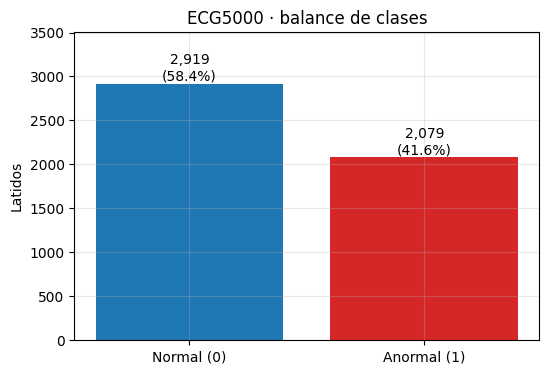

In [5]:
n_normal, n_anormal = int((y == 0).sum()), int((y == 1).sum())
print("--- Balance de clases (toda la base) ---")
print(f"Normales (0): {n_normal:,} ({n_normal / len(y):.1%})")
print(f"Anormales (1): {n_anormal:,} ({n_anormal / len(y):.1%})")
print(f"Razón normal : anormal = {n_normal / n_anormal:.2f} : 1")

# Gráfica 1: balance de clases
plt.figure(figsize=(6, 4))
barras = plt.bar(["Normal (0)", "Anormal (1)"], [n_normal, n_anormal], color=["tab:blue", "tab:red"])
for b, n in zip(barras, [n_normal, n_anormal]):
    plt.text(b.get_x() + b.get_width() / 2, n, f"{n:,}\n({n / len(y):.1%})", ha="center", va="bottom")
plt.ylim(0, max(n_normal, n_anormal) * 1.2)
plt.title("ECG5000 · balance de clases")
plt.ylabel("Latidos")
plt.show()

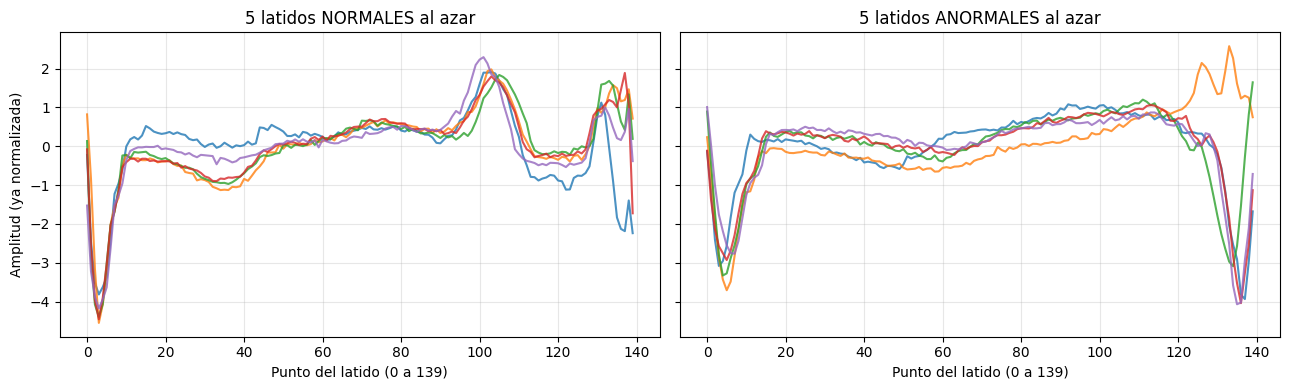

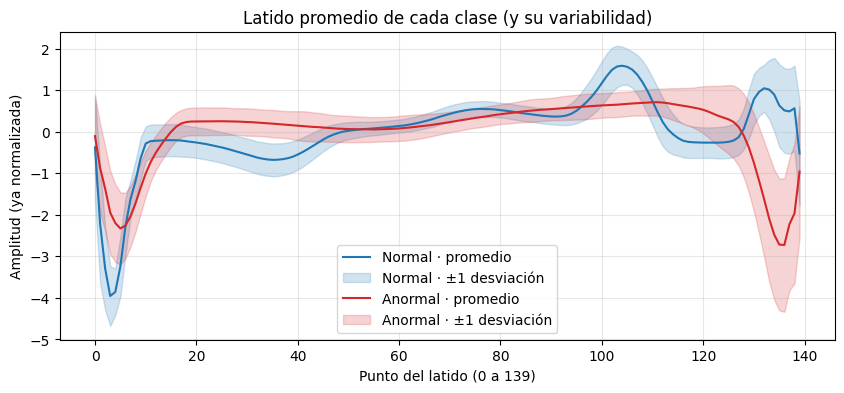

In [6]:
# Gráfica 2: ejemplos de latidos de cada clase
rng = np.random.default_rng(SEED)
ej_normal = rng.choice(np.where(y == 0)[0], 5, replace=False)
ej_anormal = rng.choice(np.where(y == 1)[0], 5, replace=False)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i in ej_normal:
    ejes[0].plot(X[i], alpha=0.8)
for i in ej_anormal:
    ejes[1].plot(X[i], alpha=0.8)
ejes[0].set_title("5 latidos NORMALES al azar")
ejes[1].set_title("5 latidos ANORMALES al azar")
for eje in ejes:
    eje.set_xlabel("Punto del latido (0 a 139)")
ejes[0].set_ylabel("Amplitud (ya normalizada)")
plt.tight_layout()
plt.show()

# Gráfica 3: latido promedio de cada clase, con su variabilidad
fig, eje = plt.subplots(figsize=(10, 4))
for clase, nombre, color in [(0, "Normal", "tab:blue"), (1, "Anormal", "tab:red")]:
    m, s = X[y == clase].mean(axis=0), X[y == clase].std(axis=0)
    eje.plot(m, color=color, label=f"{nombre} · promedio")
    eje.fill_between(range(X.shape[1]), m - s, m + s, color=color, alpha=0.2, label=f"{nombre} · ±1 desviación")
eje.set_title("Latido promedio de cada clase (y su variabilidad)")
eje.set_xlabel("Punto del latido (0 a 139)")
eje.set_ylabel("Amplitud (ya normalizada)")
eje.legend()
plt.show()

**Lectura de la exploración:** los latidos normales tienen una forma muy parecida entre sí, mientras que los anormales son más variados y suelen tener un pico en otra posición. Por eso importa **la forma de la onda completa**. Hay un desbalance leve (más normales que anormales), no un caso extremo.

> **Limitación central, que se repite en la conclusión:** todos los latidos son **de un solo paciente**. Aunque los latidos de cada clase se vean parecidos entre sí, eso no dice nada sobre otros pacientes.

## 3. Preparación: división sin fuga y transformación
1. **División indicada:** la prueba del cliente ya está apartada (`X_prueba`, `y_prueba`). Del resto (`X_resto`) se arman el **entrenamiento (80 %)** y la **validación (20 %)**, **estratificados** y con semilla, para que las dos clases conserven su proporción.
2. **Sin fuga:** la prueba no se usa para decidir nada (ni el modelo, ni la época, ni los hiperparámetros). Todo se decide con la validación. El **umbral queda fijo en 0.5**, como pide el cliente, y no se ajusta con la prueba. Aquí **se puede mezclar** al dividir, porque cada latido es una muestra independiente y no hay un "futuro" que filtrar.
3. **Transformación:** el cliente indica que los latidos **ya vienen normalizados**, así que **no se vuelve a normalizar**. Eso evita calcular estadísticos con datos de validación o prueba y deja un modelo que recibe los 140 puntos tal cual (útil para el monitor). La única transformación es darle a cada latido la forma `(140, 1)`: **140 pasos de tiempo y 1 canal**, que es lo que esperan las capas Conv1D y recurrentes.

In [7]:
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.2, stratify=y_resto,
                                                  random_state=SEED)

# Revisión de que los datos ya vienen normalizados (no se calcula nada con validación ni prueba)
print("Estadísticos del ENTRENAMIENTO (solo informativos):")
print(f"  media global: {X_train.mean():+.3f} · desviación global: {X_train.std():.3f} · "
      f"mínimo: {X_train.min():.2f} · máximo: {X_train.max():.2f}")

# Transformación: cada latido pasa a la forma (140 pasos, 1 canal)
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_prueba[..., np.newaxis]     # la prueba del cliente; solo se usa al final

tabla_division = pd.DataFrame({
    "Latidos": [len(y_train), len(y_val), len(y_prueba)],
    "Normales": [int((y_train == 0).sum()), int((y_val == 0).sum()), int((y_prueba == 0).sum())],
    "Anormales": [int((y_train == 1).sum()), int((y_val == 1).sum()), int((y_prueba == 1).sum())],
}, index=["Entrenamiento", "Validación", "Prueba (cliente)"])
tabla_division["% anormales"] = (100 * tabla_division["Anormales"] / tabla_division["Latidos"]).round(1)
print(f"\nForma de las entradas: {X_train.shape} → (latidos, puntos del latido, canales)")
display(tabla_division)

# Latido promedio de cada clase en el ENTRENAMIENTO (se usa más adelante para interpretar errores)
promedio_normal = X_train[y_train == 0, :, 0].mean(axis=0)
promedio_anormal = X_train[y_train == 1, :, 0].mean(axis=0)

Estadísticos del ENTRENAMIENTO (solo informativos):
  media global: +0.000 · desviación global: 0.996 · mínimo: -7.09 · máximo: 7.40

Forma de las entradas: (3198, 140, 1) → (latidos, puntos del latido, canales)


,Latidos,Normales,Anormales,% anormales
Entrenamiento,3198,1868,1330,41.6
Validación,800,467,333,41.6
Prueba (cliente),1000,584,416,41.6


## 4. Línea base trivial
La línea base **no aprende nada**: dice siempre la clase más frecuente del **entrenamiento** (normal). Por eso "acierta" más de la mitad de las veces, pero **no detecta ni un solo latido anormal**. Es la vara contra la que se miden los modelos.

**Métricas del cliente**, con el umbral de 0.5:
- **Sensibilidad** = verdaderos positivos ÷ (verdaderos positivos + falsos negativos): de cada 100 latidos anormales, cuántos marca.
- **Especificidad** = verdaderos negativos ÷ (verdaderos negativos + falsos positivos): de cada 100 latidos normales, cuántos deja pasar sin marcar.
- **AUC:** qué tan bien separa las dos clases con la probabilidad (0.5 = azar, 1.0 = perfecto), sin depender del umbral.

In [8]:
def metricas_cliente(y_real, prob, umbral=UMBRAL):
    """Sensibilidad, especificidad y AUC con el umbral del cliente (se marca como anormal si prob >= umbral)."""
    y_real = np.asarray(y_real).astype(int)
    prob = np.asarray(prob, dtype="float64")
    pred = (prob >= umbral).astype(int)
    tp = int(((pred == 1) & (y_real == 1)).sum())
    fn = int(((pred == 0) & (y_real == 1)).sum())
    tn = int(((pred == 0) & (y_real == 0)).sum())
    fp = int(((pred == 1) & (y_real == 0)).sum())
    sensibilidad = tp / (tp + fn) if (tp + fn) else float("nan")
    especificidad = tn / (tn + fp) if (tn + fp) else float("nan")
    return {"sensibilidad": sensibilidad, "especificidad": especificidad,
            "auc": float(roc_auc_score(y_real, prob)), "tp": tp, "fn": fn, "tn": tn, "fp": fp}


def cumple_especificaciones(m, parametros):
    """True si cumple TODAS las especificaciones del cliente (sensibilidad, especificidad y tamaño)."""
    return bool(m["sensibilidad"] >= MIN_SENSIBILIDAD and m["especificidad"] >= MIN_ESPECIFICIDAD
                and parametros <= MAX_PARAMETROS)


NOMBRE_BASE = "Línea base (clase mayoritaria)"
clase_mayoritaria = int(np.bincount(y_train).argmax())
m_base_val = metricas_cliente(y_val, np.full(len(y_val), float(clase_mayoritaria)))

# Registro de modelos: aquí se anota todo lo de la VALIDACIÓN (la prueba no se toca hasta el final)
registro = {NOMBRE_BASE: {"tipo": "linea base", "parametros": 0, "sens_val": m_base_val["sensibilidad"],
                          "esp_val": m_base_val["especificidad"], "auc_val": m_base_val["auc"],
                          "epocas": 0, "seg_epoca": np.nan}}
modelos = {}   # nombre → modelo entrenado

print(f"--- {NOMBRE_BASE} (predice siempre {'anormal' if clase_mayoritaria else 'normal'}) ---")
print(f"Validación · sensibilidad: {m_base_val['sensibilidad']:.1%} · especificidad: {m_base_val['especificidad']:.1%} · AUC: {m_base_val['auc']:.3f}")

--- Línea base (clase mayoritaria) (predice siempre normal) ---
Validación · sensibilidad: 0.0% · especificidad: 100.0% · AUC: 0.500


## 5. Modelos del parcial
Se entrenan seis arquitecturas **desde cero** con la misma receta: salida `sigmoid` (probabilidad de que el latido sea anormal), pérdida **entropía cruzada binaria**, optimizador Adam, hasta 100 épocas y `EarlyStopping` con la **validación** (restaura los mejores pesos).

| Modelo | Qué hace con el latido | Tipo |
|---|---|---|
| MLP | Aplana los 140 puntos; no sabe el orden | `mlp` |
| Conv1D | Filtros que detectan formas locales (el pico, la pendiente) | `convolucional` |
| TCN | Convoluciones causales dilatadas; el último paso ya "vio" todo el latido | `convolucional` |
| LSTM | Recorre el latido punto por punto con memoria | `recurrente` |
| GRU apilada | Dos capas GRU | `recurrente` |
| LSTM bidireccional | Lo lee de izquierda a derecha y al revés | `recurrente` |

**Todas deben caber en 20,000 parámetros**; el conteo se imprime y se verifica. La bidireccional **sí tiene sentido aquí** (a diferencia de la bolsa): el latido ya está registrado completo, no se pronostica nada.

`usar_pesos_clase` permite dar más peso a la clase minoritaria si hiciera falta para alcanzar la sensibilidad. Se deja en `False`; cambiarlo es una decisión que se toma con la validación, no con la prueba.

In [9]:
usar_pesos_clase = False
if usar_pesos_clase:
    n_tr = len(y_train)
    pesos_clase = {0: n_tr / (2 * (y_train == 0).sum()), 1: n_tr / (2 * (y_train == 1).sum())}
else:
    pesos_clase = None


def entrenar_modelo(modelo, nombre, tipo, epocas=100, paciencia=10, batch_size=64):
    """Entrena con la validación, grafica las curvas y anota las métricas de VALIDACIÓN en `registro`."""
    modelo.compile(optimizer="adam", loss="binary_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
    inicio = time.perf_counter()
    historia = modelo.fit(X_train, y_train.astype("float32"), validation_data=(X_val, y_val.astype("float32")),
                          epochs=epocas, batch_size=batch_size, shuffle=True, class_weight=pesos_clase,
                          callbacks=obtener_callbacks(nombre, paciencia=paciencia), verbose=0)
    n_epocas = len(historia.history["loss"])
    seg_por_epoca = (time.perf_counter() - inicio) / n_epocas
    graficar_curvas(historia, titulo=nombre, metrica="auc")

    parametros = int(sum(int(np.prod(w.shape)) for w in modelo.trainable_weights))
    prob_val = modelo.predict(X_val, verbose=0).ravel()
    m = metricas_cliente(y_val, prob_val)
    registro[nombre] = {"tipo": tipo, "parametros": parametros, "sens_val": m["sensibilidad"],
                        "esp_val": m["especificidad"], "auc_val": m["auc"], "epocas": n_epocas, "seg_epoca": seg_por_epoca}
    modelos[nombre] = modelo

    print(f"--- {nombre} ({tipo}) ---")
    print(f"Épocas: {n_epocas} · parámetros entrenables: {parametros:,} (límite {MAX_PARAMETROS:,}) · {seg_por_epoca:.2f} s/época")
    print(f"Validación · sensibilidad: {m['sensibilidad']:.1%} · especificidad: {m['especificidad']:.1%} · AUC: {m['auc']:.3f}")
    assert parametros <= MAX_PARAMETROS, f"{nombre} excede los {MAX_PARAMETROS:,} parámetros"
    return modelo, historia

print("Función entrenar_modelo() lista.")

Función entrenar_modelo() lista.


### 5.1 MLP
Aplana el latido en un vector de 140 valores. No sabe qué punto va antes de cuál.

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Latido (InputLayer)             │ (None, 140, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanado (Flatten)              │ (None, 140)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_64 (Dense)                │ (None, 64)             │         9,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_anormal (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,137 (43.50 KB)

 Trainable params: 11,137 (43.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 3.


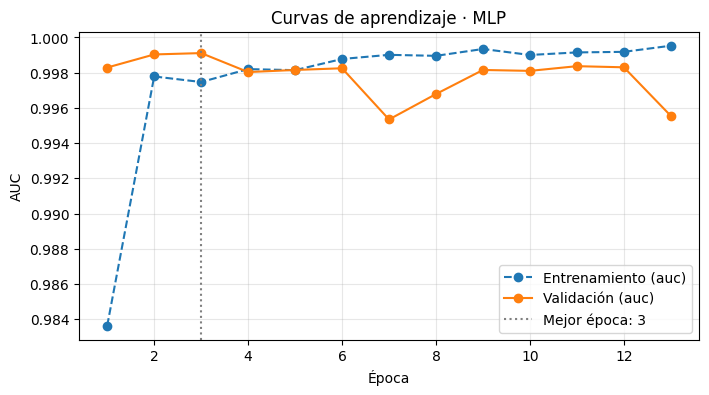

--- MLP (mlp) ---
Épocas: 13 · parámetros entrenables: 11,137 (límite 20,000) · 0.99 s/época
Validación · sensibilidad: 97.3% · especificidad: 99.1% · AUC: 0.999


In [10]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(140, 1), name="Latido")
x = layers.Flatten(name="Aplanado")(inputs)
x = layers.Dense(64, activation="relu", name="Densa_64")(x)
x = layers.Dropout(0.2, name="Dropout")(x)
x = layers.Dense(32, activation="relu", name="Densa_32")(x)
outputs = layers.Dense(1, activation="sigmoid", name="P_anormal")(x)
modelo_mlp = keras.Model(inputs, outputs, name="MLP")
modelo_mlp.summary()
modelo_mlp, historia_mlp = entrenar_modelo(modelo_mlp, "MLP", "mlp")

### 5.2 Conv1D
Dos capas convolucionales con `MaxPooling1D` entre ellas buscan formas locales del latido (el pico, la pendiente). Al final se aplana el mapa de características: así se **conserva la posición** de cada forma, que importa porque los latidos vienen alineados.

Model: "Conv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Latido (InputLayer)             │ (None, 140, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_1 (Conv1D)               │ (None, 140, 16)        │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_1 (MaxPooling1D)           │ (None, 70, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_2 (Conv1D)               │ (None, 70, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_2 (MaxPooling1D)           │ (None, 35, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanado (Flatten)              │ (None, 1120)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ (None, 1120)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_anormal (Dense)               │ (None, 1)              │         1,121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,809 (14.88 KB)

 Trainable params: 3,809 (14.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 31: early stopping
Restoring model weights from the end of the best epoch: 21.


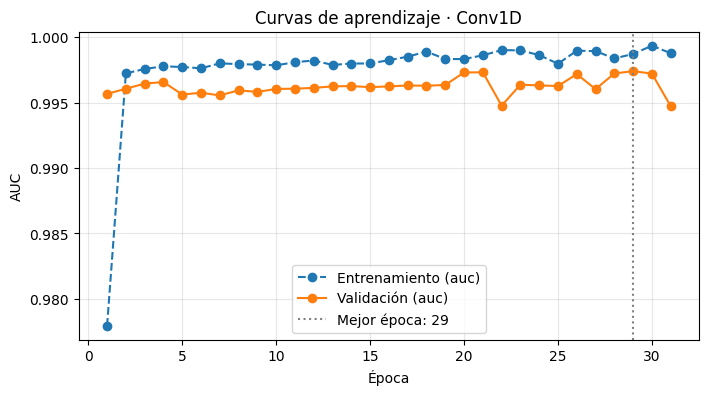

--- Conv1D (convolucional) ---
Épocas: 31 · parámetros entrenables: 3,809 (límite 20,000) · 1.08 s/época
Validación · sensibilidad: 98.5% · especificidad: 98.5% · AUC: 0.996


In [11]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(140, 1), name="Latido")
x = layers.Conv1D(16, kernel_size=5, activation="relu", padding="same", name="Conv1D_1")(inputs)
x = layers.MaxPooling1D(2, name="Pool_1")(x)
x = layers.Conv1D(32, kernel_size=5, activation="relu", padding="same", name="Conv1D_2")(x)
x = layers.MaxPooling1D(2, name="Pool_2")(x)
x = layers.Flatten(name="Aplanado")(x)
x = layers.Dropout(0.3, name="Dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="P_anormal")(x)
modelo_cnn = keras.Model(inputs, outputs, name="Conv1D")
modelo_cnn.summary()
modelo_cnn, historia_cnn = entrenar_modelo(modelo_cnn, "Conv1D", "convolucional")

### 5.3 TCN (convolución causal dilatada)
Una capa causal por cada dilatación (1, 2, 4, …), hasta que el **campo receptivo** cubra los 140 puntos del latido. Se toma **solo el último paso** de la salida, el único que "vio" todo el latido. Para eso se usa `Cropping1D`, que recorta los 139 primeros pasos y deja el último.

$$\text{RF} = 1 + (k - 1)\sum_i d_i$$

Dilataciones: [1, 2, 4, 8, 16, 32, 64] → campo receptivo 255 pasos (el latido tiene 140)


Model: "TCN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Latido (InputLayer)             │ (None, 140, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d1 (Conv1D)         │ (None, 140, 16)        │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d2 (Conv1D)         │ (None, 140, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d4 (Conv1D)         │ (None, 140, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d8 (Conv1D)         │ (None, 140, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d16 (Conv1D)        │ (None, 140, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d32 (Conv1D)        │ (None, 140, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_causal_d64 (Conv1D)        │ (None, 140, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Ultimo_paso (Cropping1D)        │ (None, 1, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanado (Flatten)              │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_anormal (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,785 (18.69 KB)

 Trainable params: 4,785 (18.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 29: early stopping
Restoring model weights from the end of the best epoch: 19.


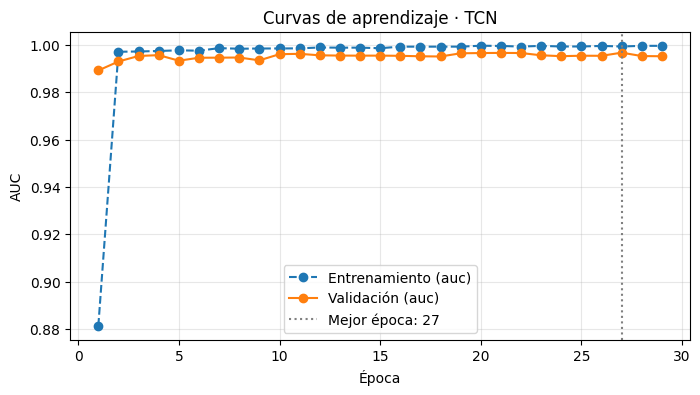

--- TCN (convolucional) ---
Épocas: 29 · parámetros entrenables: 4,785 (límite 20,000) · 1.32 s/época
Validación · sensibilidad: 98.8% · especificidad: 99.1% · AUC: 0.998


In [12]:
def campo_receptivo(k, dilataciones):
    return 1 + (k - 1) * sum(dilataciones)

LARGO_LATIDO = 140
kernel_tcn = 3
dilataciones = [1]
while campo_receptivo(kernel_tcn, dilataciones) < LARGO_LATIDO:
    dilataciones.append(dilataciones[-1] * 2)
print(f"Dilataciones: {dilataciones} → campo receptivo {campo_receptivo(kernel_tcn, dilataciones)} pasos (el latido tiene {LARGO_LATIDO})")

keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(LARGO_LATIDO, 1), name="Latido")
x = inputs
for d in dilataciones:
    x = layers.Conv1D(16, kernel_size=kernel_tcn, padding="causal", dilation_rate=d,
                      activation="relu", name=f"Conv_causal_d{d}")(x)
x = layers.Cropping1D(cropping=(LARGO_LATIDO - 1, 0), name="Ultimo_paso")(x)   # deja solo el último paso
x = layers.Flatten(name="Aplanado")(x)
outputs = layers.Dense(1, activation="sigmoid", name="P_anormal")(x)
modelo_tcn = keras.Model(inputs, outputs, name="TCN")
modelo_tcn.summary()
modelo_tcn, historia_tcn = entrenar_modelo(modelo_tcn, "TCN", "convolucional")

### 5.4 LSTM
Recorre el latido punto por punto y resume lo visto en su estado. El último estado pasa a la capa de salida.

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Latido (InputLayer)             │ (None, 140, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ LSTM_32 (LSTM)                  │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_anormal (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 58: early stopping
Restoring model weights from the end of the best epoch: 48.


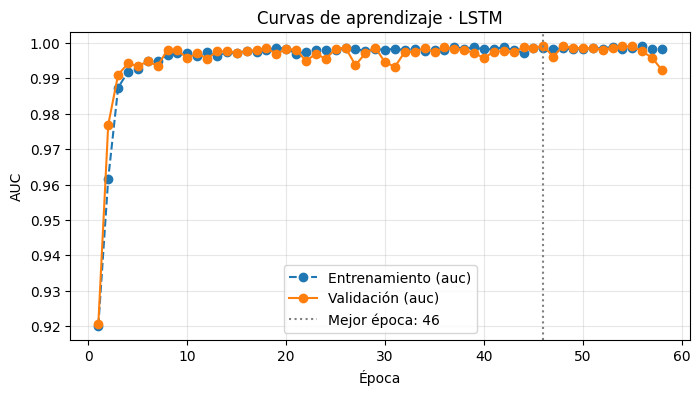

--- LSTM (recurrente) ---
Épocas: 58 · parámetros entrenables: 4,385 (límite 20,000) · 15.13 s/época
Validación · sensibilidad: 98.2% · especificidad: 99.4% · AUC: 0.999


In [13]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(140, 1), name="Latido")
x = layers.LSTM(32, name="LSTM_32")(inputs)
outputs = layers.Dense(1, activation="sigmoid", name="P_anormal")(x)
modelo_lstm = keras.Model(inputs, outputs, name="LSTM")
modelo_lstm.summary()
modelo_lstm, historia_lstm = entrenar_modelo(modelo_lstm, "LSTM", "recurrente")

### 5.5 GRU apilada
Dos capas GRU. La primera debe entregar la secuencia completa de estados (`return_sequences=True`) para que la segunda la reciba.

Model: "GRU_apilada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Latido (InputLayer)             │ (None, 140, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GRU_1_secuencia (GRU)           │ (None, 140, 32)        │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GRU_2_ultimo (GRU)              │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_anormal (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,729 (38.00 KB)

 Trainable params: 9,729 (38.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 33: early stopping
Restoring model weights from the end of the best epoch: 23.


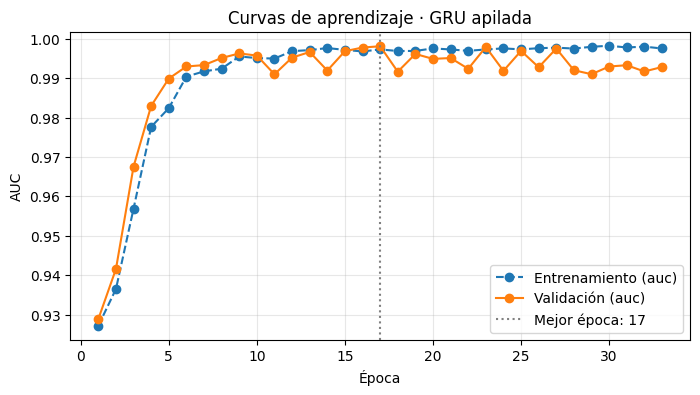

--- GRU apilada (recurrente) ---
Épocas: 33 · parámetros entrenables: 9,729 (límite 20,000) · 33.64 s/época
Validación · sensibilidad: 97.6% · especificidad: 100.0% · AUC: 0.998


In [14]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(140, 1), name="Latido")
x = layers.GRU(32, return_sequences=True, name="GRU_1_secuencia")(inputs)
x = layers.GRU(32, name="GRU_2_ultimo")(x)
outputs = layers.Dense(1, activation="sigmoid", name="P_anormal")(x)
modelo_gru = keras.Model(inputs, outputs, name="GRU_apilada")
modelo_gru.summary()
modelo_gru, historia_gru = entrenar_modelo(modelo_gru, "GRU apilada", "recurrente")

### 5.6 LSTM bidireccional
Dos LSTM leen el latido en sentidos opuestos y sus estados finales se concatenan. En el pronóstico de la bolsa no ayudaba; aquí el latido **ya está completo**, así que leer también "hacia atrás" es legítimo.

Model: "LSTM_bidireccional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Latido (InputLayer)             │ (None, 140, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ LSTM_bidireccional              │ (None, 32)             │         2,304 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ P_anormal (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,337 (9.13 KB)

 Trainable params: 2,337 (9.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 16.


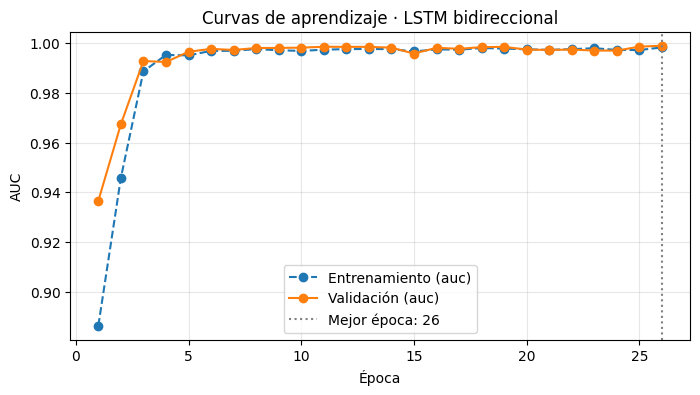

--- LSTM bidireccional (recurrente) ---
Épocas: 26 · parámetros entrenables: 2,337 (límite 20,000) · 29.60 s/época
Validación · sensibilidad: 98.2% · especificidad: 98.3% · AUC: 0.999


In [15]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(140, 1), name="Latido")
x = layers.Bidirectional(layers.LSTM(16), name="LSTM_bidireccional")(inputs)
outputs = layers.Dense(1, activation="sigmoid", name="P_anormal")(x)
modelo_bilstm = keras.Model(inputs, outputs, name="LSTM_bidireccional")
modelo_bilstm.summary()
modelo_bilstm, historia_bilstm = entrenar_modelo(modelo_bilstm, "LSTM bidireccional", "recurrente")

## 6. Elección del modelo: solo con la validación
La prueba **no interviene** en la elección. La regla es:
1. Se consideran los modelos que **cumplen las especificaciones en la validación** (sensibilidad ≥ 95 %, especificidad ≥ 95 % y ≤ 20,000 parámetros).
2. Entre ellos se elige el de **mayor AUC en validación** (desempate: menos parámetros).
3. Si ninguno las cumple, se elige el de mayor AUC en validación y **se reconoce en el folleto** que no cumple, explicando qué haría falta.

In [16]:
tabla_val = pd.DataFrame(registro).T
tabla_val["cumple_val"] = [cumple_especificaciones({"sensibilidad": r["sens_val"], "especificidad": r["esp_val"]}, r["parametros"])
                           for r in registro.values()]
tabla_val = tabla_val[["tipo", "parametros", "sens_val", "esp_val", "auc_val", "cumple_val", "epocas", "seg_epoca"]]


def elegir_modelo():
    """Elige el modelo con la validación (nunca con la prueba)."""
    candidatos = [n for n in registro if n != NOMBRE_BASE]
    cumplen = [n for n in candidatos if tabla_val.loc[n, "cumple_val"]]
    if cumplen:
        elegido = max(cumplen, key=lambda n: (tabla_val.loc[n, "auc_val"], -tabla_val.loc[n, "parametros"]))
        motivo = "cumple las especificaciones en la validación y tiene el mayor AUC entre los que las cumplen"
    else:
        elegido = max(candidatos, key=lambda n: tabla_val.loc[n, "auc_val"])
        motivo = "NINGÚN modelo cumple las especificaciones en la validación; se eligió el de mayor AUC"
    return elegido, motivo


ELEGIDO, motivo_eleccion = elegir_modelo()
print("Resultados en VALIDACIÓN (la prueba aún no se ha tocado):")
display(tabla_val.sort_values("auc_val", ascending=False).style.format(
    {"parametros": "{:,.0f}", "sens_val": "{:.1%}", "esp_val": "{:.1%}", "auc_val": "{:.3f}", "epocas": "{:.0f}", "seg_epoca": "{:.2f}"}, na_rep="—"))
print(f"\nModelo elegido con la validación: {ELEGIDO}")
print(f"Motivo: {motivo_eleccion}")

Resultados en VALIDACIÓN (la prueba aún no se ha tocado):


,tipo,parametros,sens_val,esp_val,auc_val,cumple_val,epocas,seg_epoca
LSTM,recurrente,"4,385",98.2%,99.4%,0.999,True,58,15.13
MLP,mlp,"11,137",97.3%,99.1%,0.999,True,13,0.99
LSTM bidireccional,recurrente,"2,337",98.2%,98.3%,0.999,True,26,29.60
GRU apilada,recurrente,"9,729",97.6%,100.0%,0.998,True,33,33.64
TCN,convolucional,"4,785",98.8%,99.1%,0.998,True,29,1.32
Conv1D,convolucional,"3,809",98.5%,98.5%,0.996,True,31,1.08
Línea base (clase mayoritaria),linea base,0,0.0%,100.0%,0.500,False,0,—



Modelo elegido con la validación: LSTM
Motivo: cumple las especificaciones en la validación y tiene el mayor AUC entre los que las cumplen


## 7. Resultados en la prueba del cliente
**Aquí, y solo aquí, se usa la prueba**, una sola vez por modelo y con el umbral fijo de 0.5. La tabla `resultados` lleva las columnas pedidas: `modelo`, `tipo`, `parametros`, `sensibilidad`, `especificidad`, `auc`, `cumple` (cumple **todas** las especificaciones, incluido el tamaño) y `elegido` (solo el modelo que se le vende al cliente, decidido en la sección anterior).

In [17]:
filas, probs_test = [], {}
for nombre, r in registro.items():
    if nombre == NOMBRE_BASE:
        prob = np.full(len(y_prueba), float(clase_mayoritaria))
    else:
        prob = modelos[nombre].predict(X_test, verbose=0).ravel()
    probs_test[nombre] = prob
    m = metricas_cliente(y_prueba, prob)
    filas.append({"modelo": nombre, "tipo": r["tipo"], "parametros": int(r["parametros"]),
                  "sensibilidad": m["sensibilidad"], "especificidad": m["especificidad"], "auc": m["auc"],
                  "cumple": cumple_especificaciones(m, r["parametros"]), "elegido": nombre == ELEGIDO})

resultados = pd.DataFrame(filas, columns=["modelo", "tipo", "parametros", "sensibilidad", "especificidad",
                                          "auc", "cumple", "elegido"])
resultados[["sensibilidad", "especificidad", "auc"]] = resultados[["sensibilidad", "especificidad", "auc"]].round(4)
resultados.to_csv("resultados_ecg.csv", index=False)
print(f"Guardado: {os.path.abspath('resultados_ecg.csv')}")
resultados

Guardado: /kaggle/working/resultados_ecg.csv


,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple,elegido
0,Línea base (clase mayoritaria),linea base,0,0.0000,1.0000,0.5000,False,False
1,MLP,mlp,11137,0.9880,0.9983,0.9987,True,False
2,Conv1D,convolucional,3809,0.9856,1.0000,0.9976,True,False
3,TCN,convolucional,4785,0.9856,0.9983,0.9980,True,False
4,LSTM,recurrente,4385,0.9952,0.9966,0.9983,True,True
5,GRU apilada,recurrente,9729,0.9808,0.9966,0.9980,True,False
6,LSTM bidireccional,recurrente,2337,0.9832,0.9932,0.9955,True,False


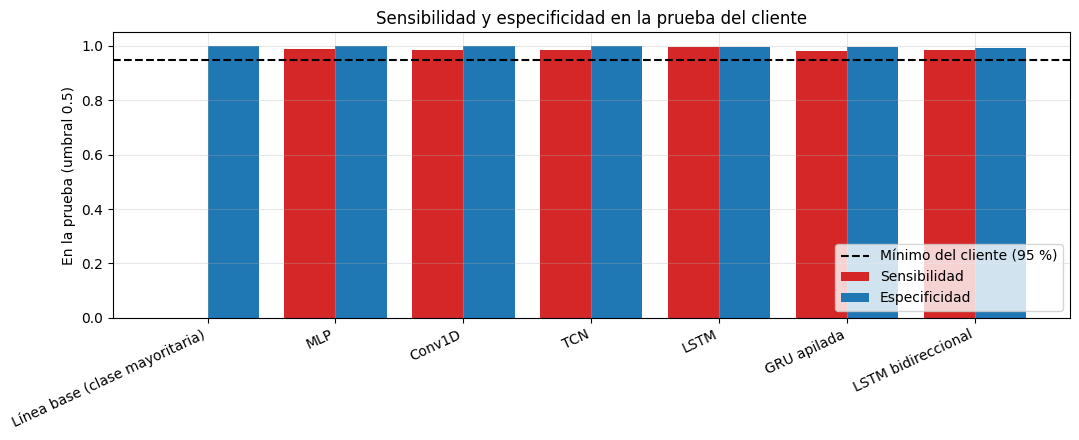

In [18]:
# Gráfica: sensibilidad y especificidad de cada modelo contra la especificación del cliente (95 %)
tabla_graf = resultados.set_index("modelo")
posiciones = np.arange(len(tabla_graf))
plt.figure(figsize=(11, 4.5))
plt.bar(posiciones - 0.2, tabla_graf["sensibilidad"], width=0.4, color="tab:red", label="Sensibilidad")
plt.bar(posiciones + 0.2, tabla_graf["especificidad"], width=0.4, color="tab:blue", label="Especificidad")
plt.axhline(MIN_SENSIBILIDAD, color="black", linestyle="--", label="Mínimo del cliente (95 %)")
plt.xticks(posiciones, tabla_graf.index, rotation=25, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("En la prueba (umbral 0.5)")
plt.title("Sensibilidad y especificidad en la prueba del cliente")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Modelo elegido: guardado y verificación
El modelo elegido se guarda en `modelo/modelo_ecg.keras`. Para comprobar que el archivo es correcto se vuelve a cargar y se compara su salida con la del modelo en memoria **en la validación** (la prueba no se vuelve a usar).

In [19]:
ruta_modelo = os.path.join(DIR_MODELO, "modelo_ecg.keras")
modelos[ELEGIDO].save(ruta_modelo)
tam_mb = os.path.getsize(ruta_modelo) / 1024**2
print(f"Modelo elegido: {ELEGIDO} → {os.path.abspath(ruta_modelo)} ({tam_mb:.2f} MB; si pesara más de 100 MB, subirlo a Hugging Face o Drive)")

cargado = keras.saving.load_model(ruta_modelo)
prob_a = modelos[ELEGIDO].predict(X_val, verbose=0).ravel()
prob_b = cargado.predict(X_val, verbose=0).ravel()
print(f"Diferencia máxima entre el modelo en memoria y el cargado de disco (validación): {np.abs(prob_a - prob_b).max():.2e}")
assert np.allclose(prob_a, prob_b, atol=1e-4), "el modelo guardado no reproduce las predicciones"
print("Verificación correcta: el archivo reproduce el modelo.")

Modelo elegido: LSTM → /kaggle/working/modelo/modelo_ecg.keras (0.08 MB; si pesara más de 100 MB, subirlo a Hugging Face o Drive)
Diferencia máxima entre el modelo en memoria y el cargado de disco (validación): 0.00e+00
Verificación correcta: el archivo reproduce el modelo.


## 9. Justificación de la elección

Se eligió la **LSTM** (tipo recurrente, 4,385 parámetros).

**Cómo se eligió.** La regla se fijó antes de ver la prueba: entre los modelos que cumplen las especificaciones en la validación, el de mayor AUC de validación. La LSTM salió elegida con esa regla. *(Sus números de validación están en la tabla de la sección 6 del cuaderno.)*

**Desempeño en la prueba del cliente (umbral 0.5).** Cada modelo se evaluó una sola vez:

| Modelo | Tipo | Parámetros | Sensibilidad | Especificidad | AUC | ¿Cumple? | Elegido |
|---|---|---:|---:|---:|---:|:---:|:---:|
| Línea base (clase mayoritaria) | linea base | 0 | 0.00 % | 100.00 % | 0.5000 | No | No |
| MLP | mlp | 11,137 | 98.80 % | 99.83 % | 0.9987 | Sí | No |
| Conv1D | convolucional | 3,809 | 98.56 % | 100.00 % | 0.9976 | Sí | No |
| TCN | convolucional | 4,785 | 98.56 % | 99.83 % | 0.9980 | Sí | No |
| **LSTM** | **recurrente** | **4,385** | **99.52 %** | **99.66 %** | **0.9983** | **Sí** | **Sí** |
| GRU apilada | recurrente | 9,729 | 98.08 % | 99.66 % | 0.9980 | Sí | No |
| LSTM bidireccional | recurrente | 2,337 | 98.32 % | 99.32 % | 0.9955 | Sí | No |

La LSTM **cumple las especificaciones** (sensibilidad ≥ 95 %, especificidad ≥ 95 % y ≤ 20,000 parámetros), con un margen amplio. La línea base tiene especificidad perfecta solo porque nunca marca nada: su sensibilidad es de 0 %.

**Desempeño en la prueba del cliente (umbral 0.5).** Sensibilidad de 99.5 %, especificidad de 99.7 % y AUC de 0.998. **Cumple las especificaciones** (95 % y 95 %), con un margen amplio.

**En palabras del cliente:** de cada 100 latidos anormales, el modelo marca 99.5; de cada 100 latidos normales, deja pasar 99.7 sin marcar. En la prueba de 1,000 latidos se equivocó en 4: dejó pasar 2 latidos anormales (de unos 416) y marcó 2 normales (de unos 584).

**Tamaño.** 4,385 parámetros, contra el límite de 20,000: cabe en el monitor con mucho margen. No es el modelo más pequeño (la LSTM bidireccional tiene 2,337 y la Conv1D 3,809), pero sí queda muy por debajo del límite.

**Comparación con las demás.**
- La **línea base** (siempre "normal") tiene sensibilidad de 0 %: no detecta ni un latido anormal, aunque "acierta" más de la mitad de las veces porque hay más latidos normales.
- Los **otros cinco modelos también cumplen** todas las especificaciones. La LSTM deja pasar 2 latidos anormales en la prueba, contra 5 del MLP, 6 de la Conv1D y la TCN, 7 de la bidireccional y 8 de la GRU apilada. Es una ventaja pequeña: con unos 416 latidos anormales, la sensibilidad tiene un margen de error de alrededor de ±1 punto, y con una sola semilla y una sola división no se puede asegurar que la LSTM sea mejor que las demás. El MLP, por ejemplo, tiene un AUC de prueba ligeramente mayor (0.9987 contra 0.9983), diferencia despreciable.

**Por qué una recurrente.** La LSTM recorre el latido punto por punto y resume lo visto en un estado, así que puede detectar en qué momento de la onda aparece la forma anormal. Dicho esto, el resultado muestra que varias arquitecturas distintas funcionan casi igual en estos datos: la elección de la LSTM se apoya sobre todo en la regla de la validación y en que su error es bajo con muy pocos parámetros, no en que una familia de modelos sea claramente superior.

## 10. Análisis de 3 errores del modelo elegido
Se muestran **3 errores** en la prueba: el falso negativo más seguro (un latido anormal que el modelo dejó pasar, el error más grave en clínica), el falso positivo más seguro (un latido normal marcado como anormal) y el siguiente error con mayor margen. Cada latido se dibuja junto al latido promedio normal y al anormal del entrenamiento.

LSTM: 4 errores de 1,000 latidos de prueba (2 falsos negativos y 2 falsos positivos)


Predicho,anormal,normal
Real,,
anormal,414,2
normal,2,582


Error 1 (latido 160 de la prueba): real = anormal · P(anormal) = 0.00 · distancia al promedio normal = 7.19, al promedio anormal = 11.58
Error 2 (latido 232 de la prueba): real = normal · P(anormal) = 0.69 · distancia al promedio normal = 7.82, al promedio anormal = 8.40
Error 3 (latido 135 de la prueba): real = anormal · P(anormal) = 0.02 · distancia al promedio normal = 4.11, al promedio anormal = 10.76


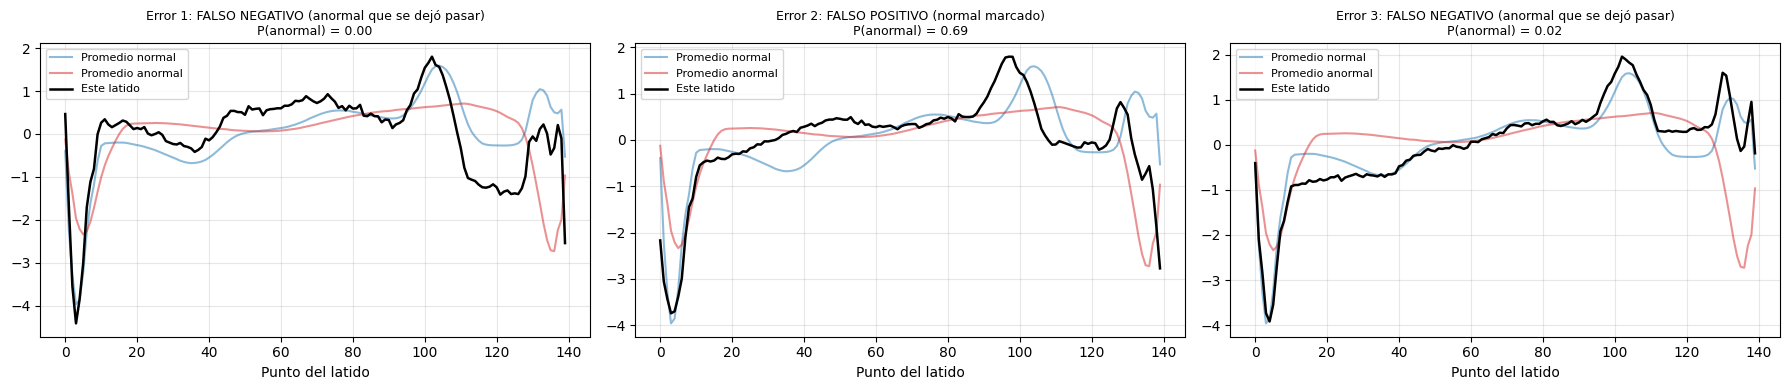

In [20]:
prob_elegido = probs_test[ELEGIDO]
pred_elegido = (prob_elegido >= UMBRAL).astype(int)
errores = np.where(pred_elegido != y_prueba)[0]
err_fn = errores[y_prueba[errores] == 1]   # falsos negativos: anormal que el modelo dejó pasar
err_fp = errores[y_prueba[errores] == 0]   # falsos positivos: normal marcado como anormal
margen = np.abs(prob_elegido - y_prueba)   # qué tan "seguro" estaba el modelo de su error

print(f"{ELEGIDO}: {len(errores)} errores de {len(y_prueba):,} latidos de prueba "
      f"({len(err_fn)} falsos negativos y {len(err_fp)} falsos positivos)")
confusion = pd.crosstab(pd.Series(y_prueba, name="Real").map({0: "normal", 1: "anormal"}),
                        pd.Series(pred_elegido, name="Predicho").map({0: "normal", 1: "anormal"}))
display(confusion)

elegidos = []
if len(err_fn):
    elegidos.append(int(err_fn[np.argmax(margen[err_fn])]))
if len(err_fp):
    elegidos.append(int(err_fp[np.argmax(margen[err_fp])]))
resto = [int(i) for i in errores[np.argsort(-margen[errores])] if int(i) not in elegidos]
elegidos = (elegidos + resto)[:3]
if len(elegidos) < 3:
    print(f"AVISO: el modelo solo cometió {len(elegidos)} error(es) en la prueba.")

fig, ejes = plt.subplots(1, max(len(elegidos), 1), figsize=(6 * max(len(elegidos), 1), 4), squeeze=False)
for n, (eje, i) in enumerate(zip(ejes[0], elegidos), 1):
    latido = X_test[i, :, 0]
    tipo_error = "FALSO NEGATIVO (anormal que se dejó pasar)" if y_prueba[i] == 1 else "FALSO POSITIVO (normal marcado)"
    eje.plot(promedio_normal, color="tab:blue", alpha=0.5, label="Promedio normal")
    eje.plot(promedio_anormal, color="tab:red", alpha=0.5, label="Promedio anormal")
    eje.plot(latido, color="black", linewidth=1.8, label="Este latido")
    eje.set_title(f"Error {n}: {tipo_error}\nP(anormal) = {prob_elegido[i]:.2f}", fontsize=9)
    eje.set_xlabel("Punto del latido")
    eje.legend(fontsize=8)
    d_normal = np.linalg.norm(latido - promedio_normal)
    d_anormal = np.linalg.norm(latido - promedio_anormal)
    print(f"Error {n} (latido {i} de la prueba): real = {'anormal' if y_prueba[i] else 'normal'} · "
          f"P(anormal) = {prob_elegido[i]:.2f} · distancia al promedio normal = {d_normal:.2f}, al promedio anormal = {d_anormal:.2f}")
plt.tight_layout()
plt.show()

**Análisis de los 3 errores** (de los 4 que cometió la LSTM en la prueba: 2 falsos negativos y 2 falsos positivos; aquí se muestran los 3 con mayor margen)

- **Error 1: falso negativo (anormal que se dejó pasar), P(anormal) = 0.00.** A simple vista, la parte principal de este latido (el pico alrededor del punto 100) sigue de cerca el **promedio normal**, y el modelo lo vio como normal con total seguridad. Lo que lo distingue es el **tramo final** (aproximadamente del punto 110 al 139), donde cae y oscila por debajo de cero, más cerca del promedio anormal. Posible causa: la anomalía de este latido es sutil y se concentra en el final, mientras que el resto de la onda es típica.
- **Error 2: falso positivo (normal marcado como anormal), P(anormal) = 0.69.** El latido tiene el pico normal cerca del punto 100, pero termina con una **caída muy profunda en los últimos puntos** (por debajo de -2), parecida a la del promedio anormal, y empieza en un valor más bajo que el promedio normal. Con 0.69 el modelo no estaba tan seguro: quedó apenas por encima del umbral de 0.5. Posible causa: una variación del final del latido que coincide con la forma típica de los anormales.
- **Error 3: falso negativo (anormal que se dejó pasar), P(anormal) = 0.02.** Es otro latido anormal que el modelo ve como normal casi con certeza. A simple vista, el latido termina cerca de cero y sin la caída final profunda del promedio anormal, así que se parece más al normal. Posible causa: igual que en el Error 1, el modelo aprendió que lo anormal suele tener la caída final y este latido no la tiene.

**Qué tipo de errores comete.**
- **Hay tantos falsos negativos como falsos positivos (2 y 2).** Los dos falsos negativos son los más graves en clínica: son latidos anormales que el monitor no marcó, y el modelo estaba casi seguro de que eran normales (P = 0.00 y 0.02), así que un umbral más bajo (por ejemplo 0.1) tampoco los habría detectado. El umbral de 0.5 lo fija el cliente.
- **Los errores parecen concentrarse en el tramo final del latido** (aproximadamente los últimos 30 puntos), que es donde el promedio normal y el anormal más se separan. Esto es una lectura de 3 latidos, no una conclusión estadística.
- **Posible etiqueta dudosa.** En los Errores 1 y 3 el latido "anormal" se parece mucho a un normal en casi toda la onda. No se puede saber sin un cardiólogo si el modelo se equivocó o si la etiqueta del dataset es discutible.
- **Con solo 4 errores, no se pueden sacar patrones firmes.** Lo que se ve es una hipótesis para revisar con más datos.

## 11. Limitaciones y ética
- **Un solo paciente (la limitación central).** Los 4,998 latidos salen del Holter de **un solo paciente** con insuficiencia cardiaca. La prueba del cliente es una división al azar de **ese mismo paciente**: sus latidos son parecidos a los del entrenamiento, y latidos vecinos en el tiempo pueden ser casi iguales. Por eso las métricas **sobrestiman** lo que pasaría con otra persona. **No se puede afirmar que el modelo funcione con otros pacientes**: otro corazón, otra anatomía, otra posición del electrodo y otro tipo de arritmia pueden cambiar la forma del latido. Para saber con qué pacientes funciona haría falta evaluarlo con registros de muchos pacientes distintos, separando **por paciente** y no por latido.
- **Margen de error.** Con unos 400 latidos anormales en la prueba, la sensibilidad tiene un margen de error de unos ±2 puntos: una diferencia pequeña entre dos modelos puede ser ruido. Además, se usó una sola semilla y una sola división.
- **El costo de los errores no es simétrico.** Un falso negativo (un latido anormal que el monitor no marca) puede dejar sin revisar un problema real; un falso positivo solo le da más trabajo al cardiólogo. Por eso la sensibilidad es la métrica más delicada.
- **Umbral fijo.** El umbral de 0.5 lo fija el cliente. Con otro umbral cambiaría el balance entre sensibilidad y especificidad; eso se decidiría con datos de validación de más pacientes, nunca con la prueba.
- **Qué hace y qué no.** El sistema **apoya** la revisión: marca latidos para que el cardiólogo los vea. No diagnostica ni sustituye al médico, y no es un dispositivo médico regulado. El tamizaje de más de 100,000 latidos por registro exige que algún humano revise lo que el modelo marque y supervise lo que deje pasar.
- **Propuesta de mejora.** Reunir registros de muchos pacientes (y de más de una marca de Holter), dividir por paciente, y medir sensibilidad y especificidad por tipo de arritmia, para saber cuáles latidos anormales detecta peor.